# Analyse univariée des variables qualitatives (catégorielles)

Objectif : décrire chaque variable qualitative **séparément** (sans croiser avec la cible) :
- tableau des effectifs, fréquences et fréquences cumulées ;
- indicateurs : nombre de modalités, mode, part du mode, entropie normalisée ;
- test d'adéquation du χ² à une répartition uniforme ;
- graphiques (diagramme en barres + secteurs) ;
- interprétation.

Variables étudiées : `Gender`, `Region`, `CityCode`, `ProvPur` (variable cible).

## 1. Chargement et préparation des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

file_id = "1n2IJtB3CaaRTvR3Rs-r3Ipns0PI5uDsc"
url = f"https://drive.google.com/uc?id={file_id}"
df = pd.read_csv(url, sep=";")

CIBLE = "ProvPur"
QUALITATIVES = ["Gender", "Region", "CityCode", CIBLE]
for c in QUALITATIVES:
    df[c] = df[c].astype("category")

print("Dimensions :", df.shape)
df[QUALITATIVES].describe()

Dimensions : (4000, 23)


,Gender,Region,CityCode,ProvPur
count,4000,4000,3903,4000
unique,2,4,19,2
top,0,NE,M,No
freq,2818,1657,234,3662


## 2. Fonctions d'analyse

In [8]:
def tableau_frequences(s):
    """Effectifs, fréquences (%) et fréquences cumulées, valeurs manquantes incluses."""
    eff = s.value_counts(dropna=False)
    t = pd.DataFrame({"Effectif": eff, "Fréquence (%)": (eff / len(s) * 100).round(2)})
    t["Fréq. cumulée (%)"] = t["Fréquence (%)"].cumsum().round(2)
    t.index = t.index.astype(object).where(t.index.notna(), "Manquant")
    return t


def indicateurs(s):
    """Indicateurs de synthèse d'une variable qualitative (hors valeurs manquantes)."""
    eff = s.value_counts()
    p = eff / eff.sum()
    k = len(eff)
    entropie = -(p * np.log(p)).sum() / np.log(k) if k > 1 else 0.0
    chi2 = stats.chisquare(eff)            # H0 : toutes les modalités sont équiprobables
    return pd.Series({
        "Nb modalités": k,
        "Valeurs manquantes": s.isna().sum(),
        "Mode": eff.idxmax(),
        "Part du mode (%)": round(p.max() * 100, 2),
        "Modalité la plus rare": eff.idxmin(),
        "Part la plus rare (%)": round(p.min() * 100, 2),
        "Ratio max/min": round(eff.max() / eff.min(), 2),
        "Entropie normalisée": round(entropie, 3),   # 1 = parfaitement équilibré, 0 = une seule modalité
        "Chi2 uniformité": round(chi2.statistic, 2),
        "p-value": chi2.pvalue,
        "Répartition uniforme ?": chi2.pvalue > 0.05,
    })


def graphiques(s, titre=None):
    eff = s.value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
    ax = sns.barplot(x=eff.index.astype(str), y=eff.values, ax=axes[0],
                     color="steelblue", order=eff.index.astype(str))
    for i, v in enumerate(eff.values):
        ax.text(i, v, f"{v}\n({v / eff.sum():.1%})", ha="center", va="bottom", fontsize=8)
    ax.axhline(eff.mean(), color="red", ls="--", label="répartition uniforme")
    ax.set_ylabel("Effectif"); ax.legend(); ax.set_title("Effectifs par modalité")
    ax.margins(y=0.15)
    if len(eff) <= 6:
        axes[1].pie(eff.values, labels=eff.index.astype(str), autopct="%1.1f%%", startangle=90)
        axes[1].set_title("Répartition (%)")
    else:
        axes[1].set_visible(False)
    fig.suptitle(titre or s.name, fontsize=14)
    plt.tight_layout(); plt.show()

## 3. Synthèse de toutes les variables qualitatives

In [3]:
synthese = pd.DataFrame({c: indicateurs(df[c]) for c in QUALITATIVES}).T
display(synthese)

,Nb modalités,Valeurs manquantes,Mode,Part du mode (%),Modalité la plus rare,Part la plus rare (%),Ratio max/min,Entropie normalisée,Chi2 uniformité,p-value,Répartition uniforme ?
Gender,2,0,0,70.45,1,29.55,2.38,0.876,669.12,0.0,False
Region,4,0,NE,41.42,NW,5.7,7.27,0.881,1124.56,0.0,False
CityCode,19,97,M,6.0,K,4.28,1.4,0.999,22.9,0.194369,True
ProvPur,2,0,No,91.55,Yes,8.45,10.83,0.418,2762.24,0.0,False


**Lecture du tableau de synthèse**
- **Entropie normalisée** : proche de 1 → modalités équilibrées ; proche de 0 → une modalité écrase les autres.
- **Test du χ² d'uniformité** : p-value < 0,05 → on rejette l'hypothèse d'une répartition égale entre modalités.
- **Ratio max/min** : écart entre la modalité la plus fréquente et la plus rare.
- Les parts de ce tableau sont calculées **hors valeurs manquantes** ; celles des tableaux de fréquences ci-dessous le sont sur **l'ensemble des 4 000 clients**.

## 4. Variable `Gender` (genre)

,Effectif,Fréquence (%),Fréq. cumulée (%)
Gender,,,
0,2818,70.45,70.45
1,1182,29.55,100.00


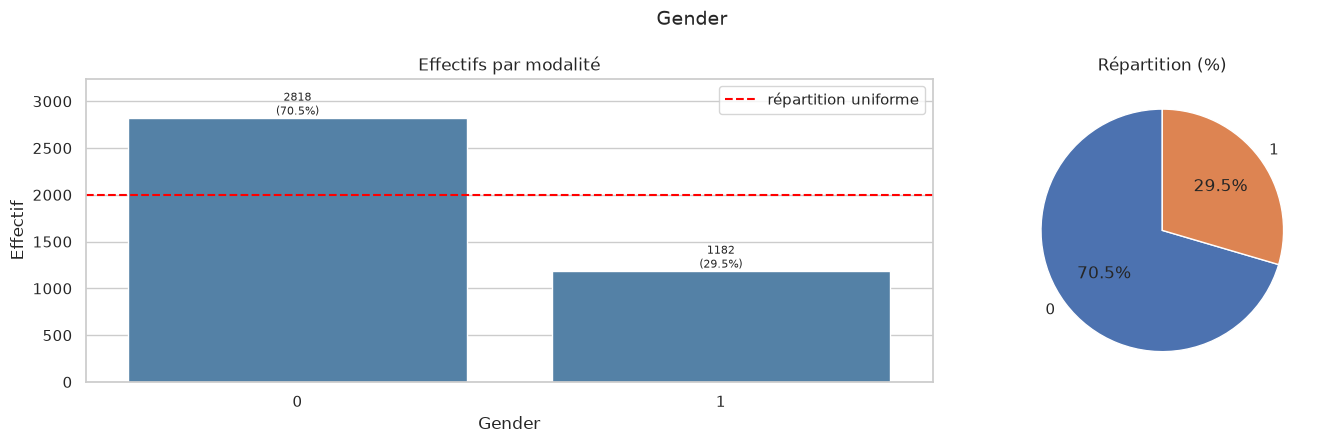

In [4]:
display(tableau_frequences(df["Gender"]))
graphiques(df["Gender"], "Gender")

### Interprétation — `Gender`
- Variable **binaire** codée 0 / 1, sans valeur manquante.
- La modalité **0** est largement majoritaire : **2 818 clients (70,45 %)** contre **1 182 (29,55 %)** pour la modalité 1, soit un rapport d'environ **2,4 pour 1**.
- Le test du χ² d'uniformité (χ² ≈ 669, p ≈ 0) rejette nettement l'hypothèse d'une répartition 50/50 : le déséquilibre est **réel**, il ne s'explique pas par le hasard.
- ⚠️ Le sens du codage (0 = homme ou femme ?) doit être confirmé dans le dictionnaire des données avant toute conclusion sur le profil de la clientèle.
- Conséquence : dans les analyses bivariées, il faudra raisonner en **taux** (pourcentages par genre) et non en effectifs bruts.

## 5. Variable `Region` (région)

,Effectif,Fréquence (%),Fréq. cumulée (%)
Region,,,
NE,1657,41.42,41.42
SW,1270,31.75,73.17
SE,845,21.12,94.29
NW,228,5.70,99.99


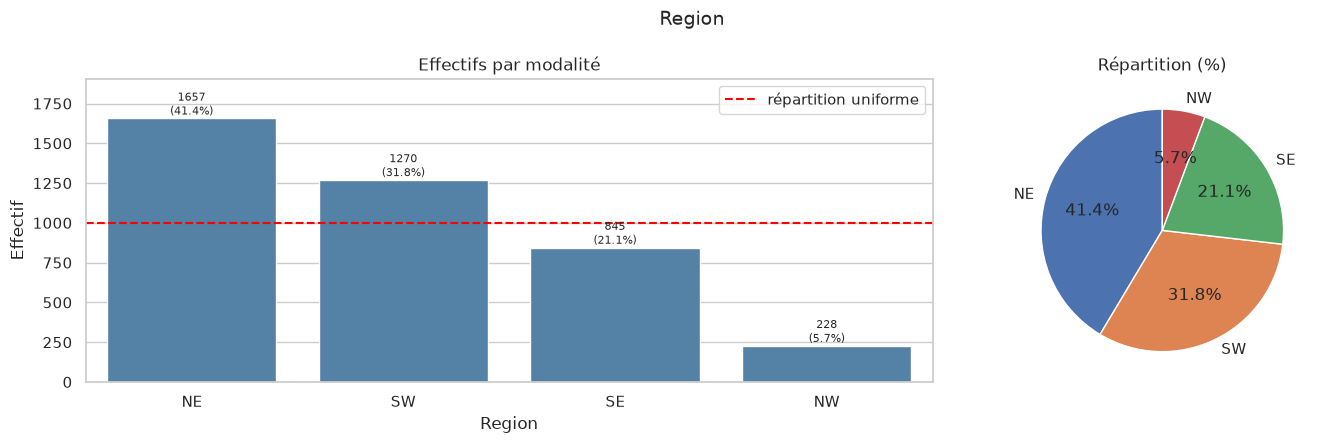

In [5]:
display(tableau_frequences(df["Region"]))
graphiques(df["Region"], "Region")

### Interprétation — `Region`
- 4 modalités (NE, SW, SE, NW), aucune valeur manquante.
- **NE** est la région dominante avec **1 657 clients (41,42 %)**, suivie de **SW (31,75 %)** et **SE (21,12 %)**. Ces trois régions regroupent **94,3 %** de la clientèle.
- **NW** est très peu représentée : **228 clients (5,70 %)**, soit environ **7 fois moins** que NE.
- Le test du χ² (χ² ≈ 1 125, p ≈ 0) confirme que la répartition est **très inégale**.
- Conséquence : les résultats concernant NW reposent sur un petit effectif et seront **moins fiables** (forte variabilité des taux). Selon l'objectif, on peut envisager de regrouper NW avec une région voisine.

## 6. Variable `CityCode` (code ville)

,Effectif,Fréquence (%),Fréq. cumulée (%)
CityCode,,,
M,234,5.85,5.85
N,224,5.60,11.45
I,223,5.58,17.03
C,219,5.48,22.51
L,219,5.48,27.99
F,216,5.40,33.39
H,213,5.32,38.71
S,209,5.22,43.93
E,206,5.15,49.08


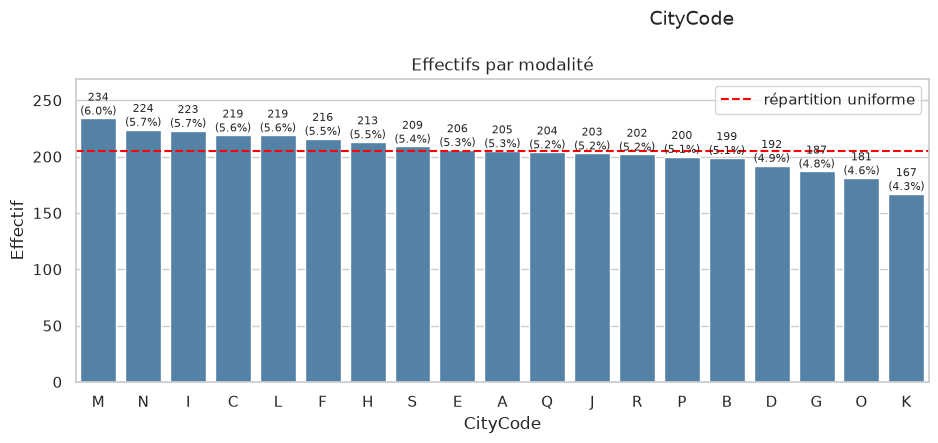

In [6]:
display(tableau_frequences(df["CityCode"]))
graphiques(df["CityCode"], "CityCode")

### Interprétation — `CityCode`
- **19 modalités** (lettres A à S) : c'est la variable qualitative la plus détaillée.
- **97 valeurs manquantes (2,43 %)**, une proportion faible : on peut les supprimer ou les regrouper dans une modalité « Inconnu » sans fausser l'analyse.
- La répartition est **quasi uniforme** : chaque ville représente entre **4,18 % (K, 167 clients)** et **5,85 % (M, 234 clients)** ; le ratio max/min n'est que de 1,4.
- L'entropie normalisée (≈ 0,999) et le test du χ² (χ² ≈ 22,9, **p ≈ 0,19 > 0,05**) indiquent qu'on **ne peut pas rejeter** l'hypothèse d'une répartition égale entre les villes.
- Conséquence : aucune ville ne domine. Prise seule, `CityCode` apporte **peu d'information**. Avec 19 modalités, elle risque surtout d'alourdir un modèle : à n'utiliser que si l'analyse bivariée montre un lien avec la cible.

## 7. Variable cible `ProvPur` (achat provincial)

,Effectif,Fréquence (%),Fréq. cumulée (%)
ProvPur,,,
No,3662,91.55,91.55
Yes,338,8.45,100.00


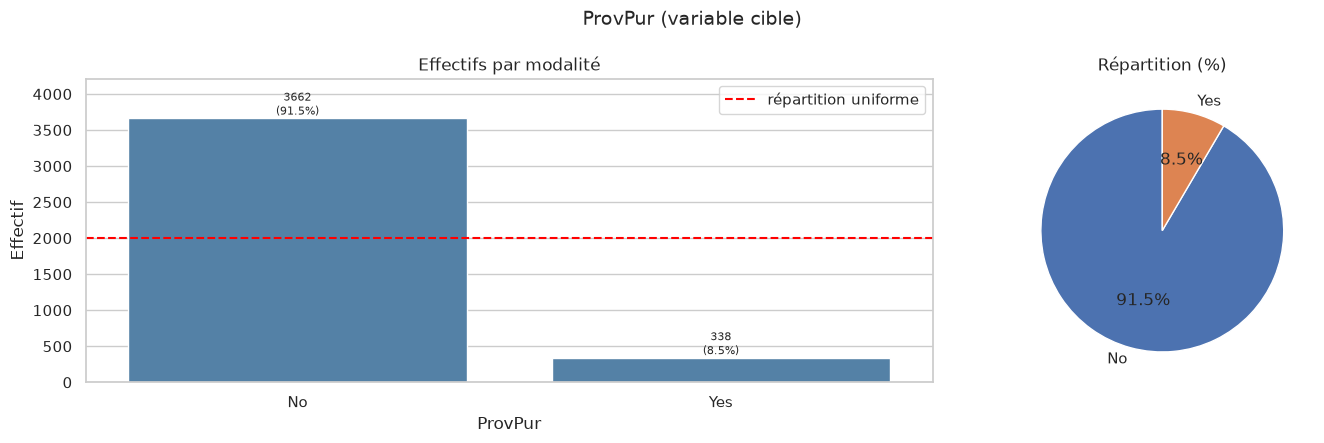

In [7]:
display(tableau_frequences(df[CIBLE]))
graphiques(df[CIBLE], "ProvPur (variable cible)")

### Interprétation — `ProvPur`
- Variable cible **binaire** (Yes / No), sans valeur manquante.
- **Seulement 338 clients (8,45 %)** ont réalisé un achat provincial, contre **3 662 (91,55 %)** qui n'en ont pas fait, soit environ **1 acheteur pour 11 non-acheteurs**.
- L'entropie normalisée est faible (≈ 0,42) et le test du χ² est extrêmement significatif : la cible est **fortement déséquilibrée**.
- Conséquences pour la suite :
  - un modèle naïf qui prédirait toujours « No » aurait déjà **91,5 % d'exactitude** : l'*accuracy* n'est donc pas un bon indicateur. Il faut plutôt regarder le **rappel**, la **précision**, le **F1-score** ou l'**AUC** sur la classe « Yes » ;
  - il faut prévoir un **échantillonnage stratifié** (train/test) et éventuellement un rééquilibrage (pondération des classes, sur- ou sous-échantillonnage).

## 8. Conclusion de l'analyse univariée qualitative

| Variable | Modalités | Manquants | Constat principal |
|---|---|---|---|
| `Gender` | 2 | 0 | Déséquilibré : 70 % / 30 % |
| `Region` | 4 | 0 | NE majoritaire (41 %), NW marginale (6 %) |
| `CityCode` | 19 | 97 (2,4 %) | Répartition uniforme (≈ 5 % par ville), peu informative seule |
| `ProvPur` | 2 | 0 | Cible très déséquilibrée : 8,45 % de « Yes » |

**À retenir** : la cible est rare, donc les analyses suivantes (bivariées et modélisation) doivent raisonner en **taux** et utiliser des métriques adaptées aux classes déséquilibrées. Les petits effectifs (région NW) sont à interpréter avec prudence.